# Предобработка данных

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cut_tree
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

In [86]:
df = pd.read_csv('digit.dat', sep=';')
df.head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Столбцы дублируются, посмотрим столбцы, в которых значения в дублирующих столбцах разные 

In [87]:
cols = ["A", "B", "C", "D", "E", "F", "G", "H"]

mask = (df[cols].to_numpy() != df[[col + '2' for col in cols]].to_numpy()).any(axis=1)

df.loc[mask].head()

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Визуально столбцы ничем не отличаюся, но сранение говорит, что они не одинаковые. Скорее всего где то есть пробельные символы по краям

In [88]:
df.head().map(repr)

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2
0,'seven','ONE ','ZERO','ONE ','ZERO','ZERO','ONE ','ZERO','seven','ONE','ZERO','ONE','ZERO','ZERO','ONE','ZERO'
1,'one ','ZERO','ZERO','ONE ','ZERO','ZERO','ONE ','ZERO','one','ZERO','ZERO','ONE','ZERO','ZERO','ONE','ZERO'
2,'four ','ZERO','ONE ','ONE ','ONE ','ZERO','ONE ','ZERO','four','ZERO','ONE','ONE','ONE','ZERO','ONE','ZERO'
3,'two ','ONE ','ONE ','ONE ','ONE ','ONE ','ZERO','ZERO','two','ONE','ONE','ONE','ONE','ONE','ZERO','ZERO'
4,'eight','ZERO','ONE ','ONE ','ONE ','ONE ','ONE ','ONE ','eight','ZERO','ONE','ONE','ONE','ONE','ONE','ONE'


Да, видно что есть лишние пробельные символы в левых колонках. Удалим их и выполним сравнение снова

In [89]:
df = df.apply(lambda col: col.str.strip())

In [90]:
cols = ["A", "B", "C", "D", "E", "F", "G", "H"]

mask = (df[cols].to_numpy() != df[[col + '2' for col in cols]].to_numpy()).any(axis=1)

df.loc[mask]

,A,B,C,D,E,F,G,H,A2,B2,C2,D2,E2,F2,G2,H2


Теперь видно, что леввая половина столбцов совпадает с правой половиной, значит можно удалить дубликаты

In [91]:
df = df[cols]
df.head()

,A,B,C,D,E,F,G,H
0,seven,ONE,ZERO,ONE,ZERO,ZERO,ONE,ZERO
1,one,ZERO,ZERO,ONE,ZERO,ZERO,ONE,ZERO
2,four,ZERO,ONE,ONE,ONE,ZERO,ONE,ZERO
3,two,ONE,ONE,ONE,ONE,ONE,ZERO,ZERO
4,eight,ZERO,ONE,ONE,ONE,ONE,ONE,ONE


Заменим числительные на цифры

In [92]:
df = df.replace({"ZERO": 0, "ONE": 1, "zero": 0,
             "one": 1, "two": 2, "three": 3,
             "four": 4, "five": 5, "six": 6,
             "seven": 7, "eight": 8, "nine": 9})
df = df.astype(int)
df.head()

,A,B,C,D,E,F,G,H
0,7,1,0,1,0,0,1,0
1,1,0,0,1,0,0,1,0
2,4,0,1,1,1,0,1,0
3,2,1,1,1,1,1,0,0
4,8,0,1,1,1,1,1,1


### Выбор метрики расстояния: 
Данные категориальные, значит подойдут следующие метрики Хэмминга и Жаккара.  
Хэмминг (доля несовпадающих координат): 
$$
d(x,y) = \frac{1}{d}\sum_{i=1}^{d}\mathbf{1}[x_i \neq y_i]
$$
Жаккар (сходство между множествами): 
$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|},
\qquad d(x,y) = 1 - J
$$  
Проделаем кластеризацию с обоими метриками и сравним результаты.  
### Выбор метода определения межкластерного расстояния:  
Выберем метод Average linkage:
$$
D(C_i,C_j)=\frac{1}{|C_i||C_j|}\sum_{x\in C_i}\sum_{y\in C_j}d(x,y)
$$
Он хорошо подходит под эту задачу так как:
- Находит компактные кластеры, в отличие от single linkage
- На него слабо влияют выбросы, в отличие от сomplete linkage
- Позволяет использовать различные метрики расстояния, в отличие от Ward  

# Иерархическая кластеризация

Удалим группирующую переменную, в кластеризации она не используется

In [93]:
df_train = df.loc[:, "B":"H"]

Проведем кластеризацию

In [94]:
K_VALUES = np.arange(2, 16)

In [95]:
# Функция для кластеризации
def clastering(df, method, metric):
    df = df.astype(bool)
    link = linkage(df, method=method, metric=metric)
    silhouette_data = []

    # Расчитаем коэффициент силуэта для различных k
    for k in K_VALUES:
        labels = cut_tree(link, n_clusters=k).ravel()
        score = silhouette_score(df, labels, metric=metric)
        silhouette_data.append({"n_clusters": k, "silhouette": score})

    silhouette_data = pd.DataFrame(silhouette_data)
    return link, silhouette_data

In [96]:
hamming_data = {"method": "Hamming"}
jaccard_data = {"method": "Jaccard"}

# Выполним кластеризацию для метрики Хэмминга
link, silhouette = clastering(df_train, 'average', 'hamming')
hamming_data["link"] = link
hamming_data["silhouette"] = silhouette

# Выполним кластеризацию для метрики Жаккара
link, silhouette = clastering(df_train, 'average', 'jaccard')
jaccard_data["link"] = link
jaccard_data["silhouette"] = silhouette

In [97]:
plt.style.use('seaborn-v0_8')
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.grid": True,
})

Построим дендрограммы для обоих метрик расстояния

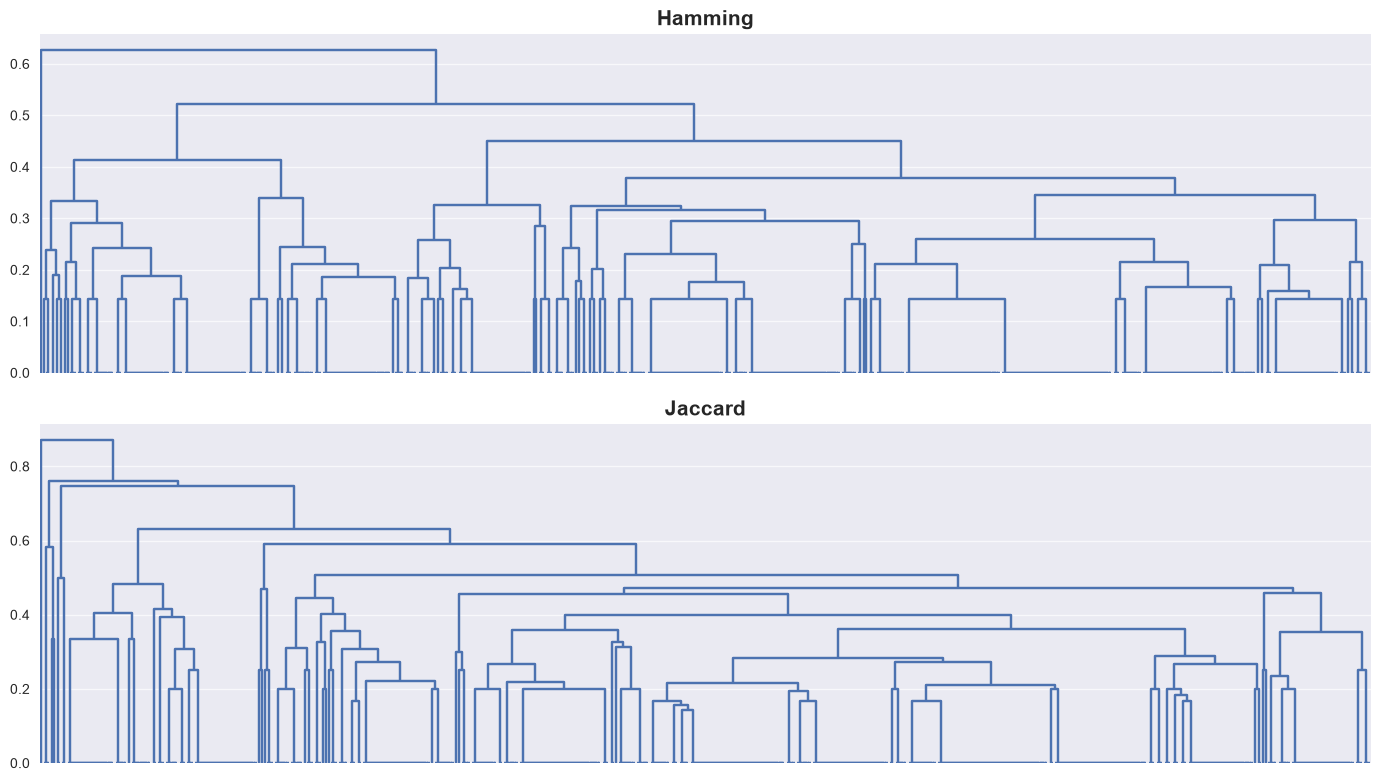

In [98]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for i, data in enumerate((hamming_data, jaccard_data)):
    dendrogram(data["link"], ax = axes[i], color_threshold=-1, no_labels=True)
    axes[i].set_title(data["method"])

plt.tight_layout()
plt.show()

По дендрограммам тяжело определить количество кластеров. Построим графики силуэта и каменистой осыпи

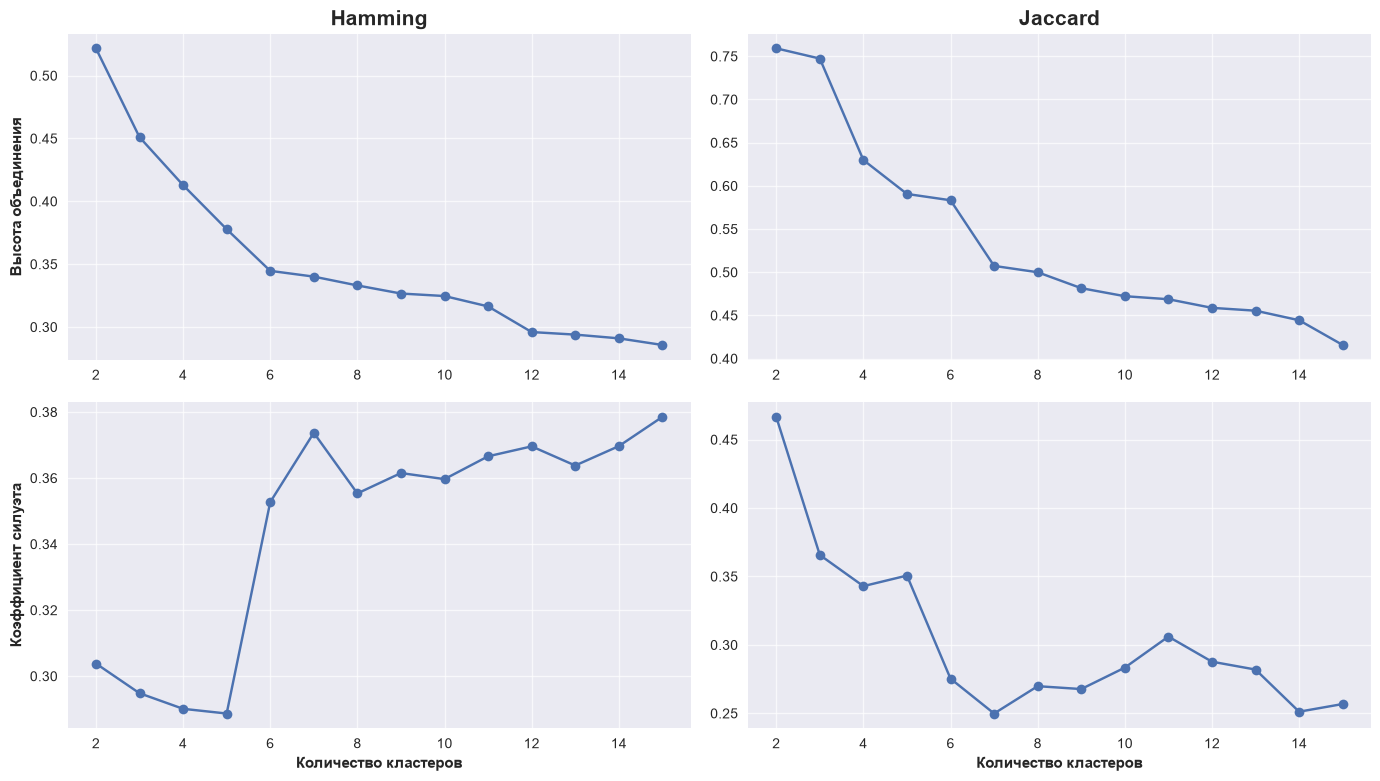

In [99]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, data in enumerate((hamming_data, jaccard_data)):
    heights = data["link"][-K_VALUES, 2]

    axes[0, i].plot(K_VALUES, heights, marker='o')
    axes[0, i].set_title(data["method"])


    axes[1, i].plot(
        data["silhouette"]["n_clusters"],
        data["silhouette"]["silhouette"],
        marker='o'
    )

    axes[1, i].set_xlabel("Количество кластеров")

axes[0, 0].set_ylabel("Высота объединения")
axes[1, 0].set_ylabel("Коэффициент силуэта")

plt.tight_layout()
plt.show()

Претенденты на итоговое количество кластеров:  
Для метрики Хэмминга: K = {6, 7}  
Для метрики Жаккара: K = {5, 7}  
Посмотрим как разрежутся дендрограммы при таких K 

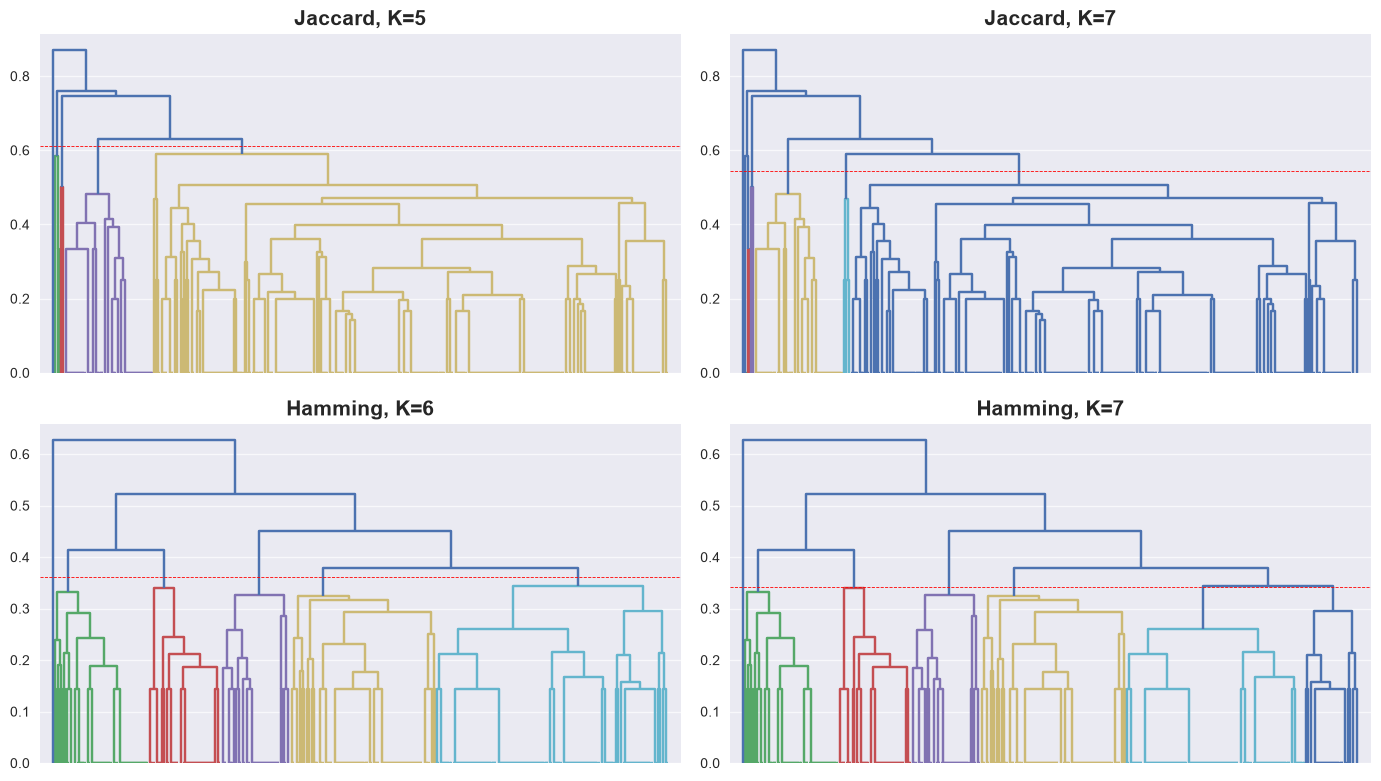

In [100]:
params = [
    (jaccard_data, 5),
    (jaccard_data, 7),
    (hamming_data, 6),
    (hamming_data, 7)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (data, k) in zip(axes.ravel(), params):
    link = data["link"]

    # Берем среднее между 2мя высотами объединения кластеров
    threshold = (link[-k, 2] + link[-k + 1, 2]) / 2

    dendrogram(link, ax=ax, color_threshold=threshold, no_labels=True)

    ax.axhline(threshold, color="red", linestyle="--", linewidth=0.6)
    ax.set_title(f'{data["method"]}, K={k}', fontweight="bold")

    left, right = ax.get_xlim()
    ax.set_xlim(left - 100, right + 100)

plt.tight_layout()
plt.show()

По графиком видно, что при выборе метрики Жаккара кластеры получаются неравномерные (1 очень большой кластер и несколько маленьких), а при выборе метрики Хэмминга кластеры достаточно равномерные. Рассмотрим далее метрику Хэмминга и количество кластеров 6 и 7.

In [101]:
labels_6 = cut_tree(hamming_data["link"], n_clusters=6).ravel()
labels_7 = cut_tree(hamming_data["link"], n_clusters=7).ravel()

# Размеры кластеров при K = 6
pd.Series(labels_6).value_counts().sort_index()

0     77
1     59
2     56
3    118
4    189
5      1
Name: count, dtype: int64

In [102]:
# Размеры кластеров при K = 7
pd.Series(labels_7).value_counts().sort_index()

0     77
1     59
2     56
3    118
4    146
5     43
6      1
Name: count, dtype: int64

Видно, что при 7 кластреах от 4го кластера отделилось 43 элемента и образовало новый кластер, а также, что в обоих случаях есть кластер из одного элемнта.  Посмотрим на распределение цифр по кластерам

In [103]:
def hmap(labels):
    table = pd.crosstab(labels, df["A"].to_numpy(), normalize="index") * 100
    
    plt.figure(figsize=(12, 6))
    
    sns.heatmap(
        table,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        linewidths=0.5
    )
    
    plt.xlabel("Правильная цифра")
    plt.ylabel("Кластер")
    plt.title(f"Распределение цифр по кластерам, %. K={max(labels) + 1}")
    plt.show()

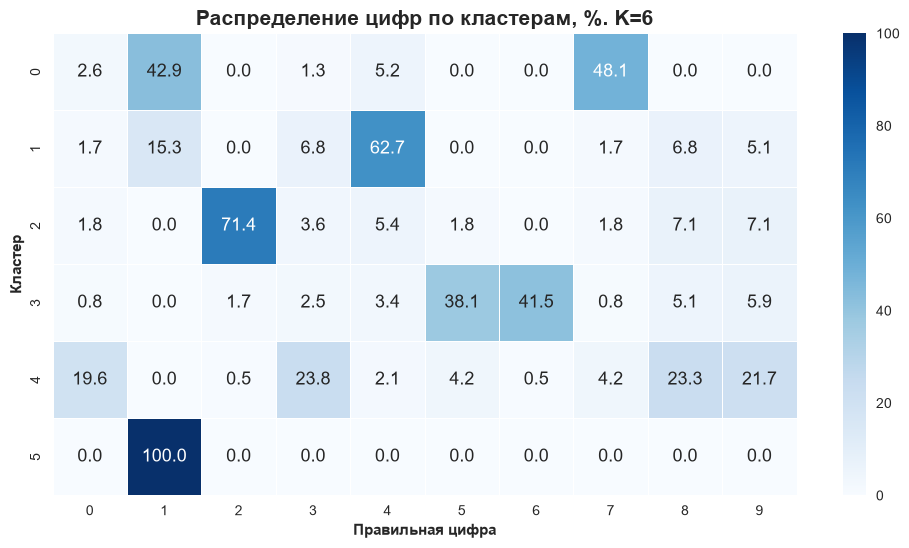

In [104]:
hmap(labels_6)

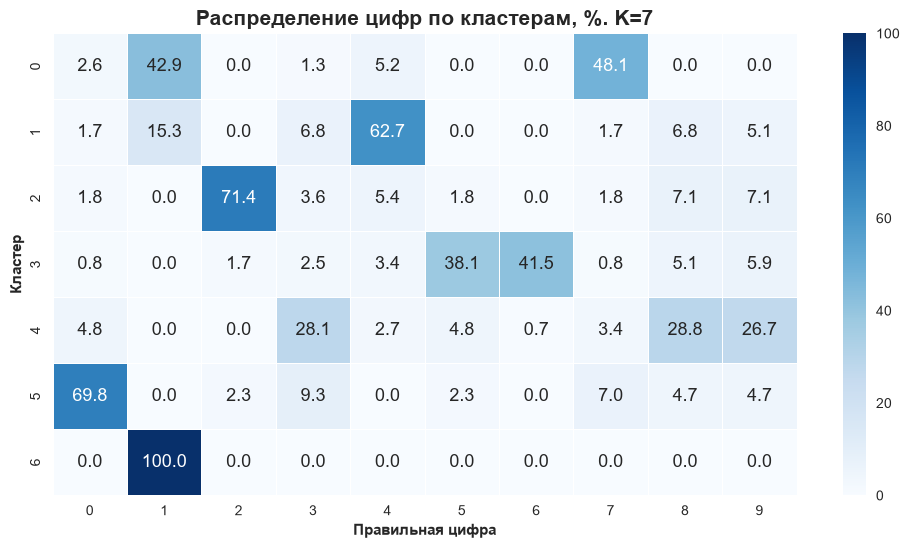

In [105]:
hmap(labels_7)

Видно, что при увеличении количества кластеров с 6 до 7 происходит выделение цифры 0 в отдельную группу.  
По этой причине отдадим предпочтение 7ми кластерам, к тому же при 7ми кластерах больше коэффициент силуэта

In [106]:
# Посмотрим на 6 кластер
idx = np.where(labels_7 == 6)[0]
display(df_train.iloc[idx])

,B,C,D,E,F,G,H
348,0,0,0,0,0,0,1


Итоговые кластеры и цифры попавшие в них:  
0 кластер: 1, 7  
1 кластер: 4  
2 кластер: 2  
3 кластер: 5, 6  
4 кластер: 3, 8, 9  
5 кластер: 0  
6 кластер: выброс  


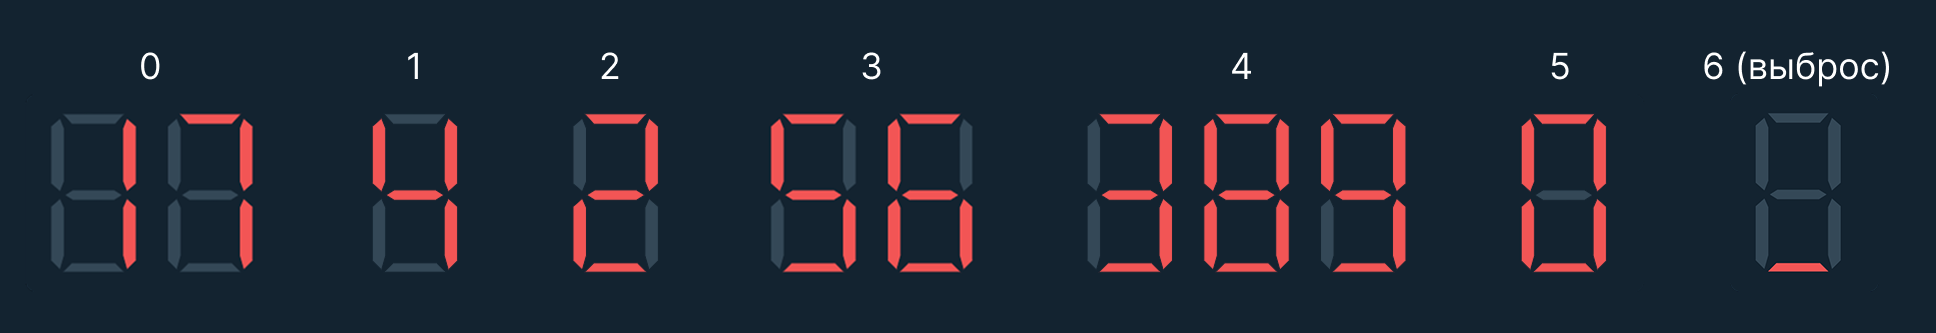  
В кластерах находятся похожие цифры

# Вывод

В ходе лабораторной работы была выполнена иерархическая кластеризация изображений цифр с помощью метрик Хэмминга и Жаккара.

По результатам сравнения была выбрана метрика Хэмминга, так как она позволила получить более равномерные по размеру кластеры. Данные делились на 6 и 7 кластеров, для итогового результата было выбрано 7 кластеров, так как это позволило выделить отдельную группу для цифры 0.

В одни кластеры попали цифры с похожим расположением сегментов. Также был обнаружен кластер из одного наблюдения, который можно считать выбросом. При этом кластеры не состоят исключительно из определённых цифр: в них также встречаются небольшие доли других цифр. Это может быть связано с ошибками считывания сегментов, из-за которых изображения некоторых цифр становятся более похожими и попадают в один кластер.